# Predictive Risk Identification for Diabetes and Heart Disease
## Stage 2 Technical Report & Laboratory Notebook: Clustering, Dimensionality Reduction, and Outlier Detection

**Topic:** Unsupervised Phenotyping, Manifold Mapping, and Anomaly Diagnostics for Cardiometabolic Disease Risk  
**Course Project Stage:** Stage 2 Deliverable  
**Core Technologies:** Python 3, Pandas, NumPy, Scikit-Learn, SciPy, Matplotlib, Seaborn  
**Random State:** 42 (Enforced globally across all stochastic seeds)  

---

### Executive Overview & Scientific Scope
Cardiometabolic conditions—primarily Type 2 Diabetes Mellitus (T2D) and Coronary Heart Disease (CHD)—share common pathophysiological drivers including visceral adiposity, insulin resistance, atherogenic dyslipidemia, and arterial hypertension.

Building upon **Mid-Report 1** (which audited 652 hidden zeros in clinical biometrics, evaluated missing data science across surveys, and mined frequent itemsets via Apriori and FP-Growth), this **Stage 2 Notebook** implements three core unsupervised data mining pillars:
1. **Clustering Analysis**: Delineating patient risk phenotypes using **K-Means**, **Hierarchical Agglomerative Clustering (Ward linkage)**, and **DBSCAN (density-based)**, validated on population (BRFSS) and clinical lab cohorts (Cleveland Heart Disease and Pima Indians Diabetes).
2. **Dimensionality Reduction**: Untangling multi-collinear predictors and projecting high-dimensional manifolds into interpretable 2D/3D spaces using **Principal Component Analysis (PCA)** and **t-Distributed Stochastic Neighbor Embedding (t-SNE)**.
3. **Outlier Detection**: Distinguishing genuine pathological extremes (e.g., morbid obesity, acute glycemic crisis) from impossible entry artifacts using **Isolation Forests** and **Local Outlier Factor (LOF)**, and evaluating model stability before versus after outlier removal.
4. **Integration & Translation**: Synthesizing findings into actionable clinical decision support rules for the **Dietify** digital health mobile app.


## 0. Setup and Environment Configuration
We configure the runtime environment, set visual styling parameters, define directory paths, and enforce `random_state=42` across all random number generators.


In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.manifold import TSNE
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Suppress harmless OpenBLAS warnings on macOS
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Set random seed for 100% reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "figure.titlesize": 12,
})

CLEAN_DIR = Path("data/clean")
TBL_DIR = Path("outputs/tables")
FIG_DIR = Path("outputs/figures")

print("Stage 2 Environment successfully initialized. Reproducibility seed = 42.")


Stage 2 Environment successfully initialized. Reproducibility seed = 42.


### 0.1 Loading Cleaned Cohorts from Mid-Report 1
We load the preprocessed datasets created during Mid-Report 1:
- **Primary Multi-Risk Cohort (CDC BRFSS 2015, Sample N=5,000)**: Complete lifestyle, demographic, and multi-disease survey records.
- **Cleveland Heart Disease Cohort (N=297)**: Clinical cardiac catheterization evaluations.
- **Pima Indians Diabetes Cohort (N=768)**: Clinical lab biometrics (with median imputation applied to missing lab tests for distance-based ML).


In [2]:
# 1. Primary Population Cohort
brfss_full = pd.read_csv(CLEAN_DIR / "brfss_clean.csv")
pop_df = brfss_full.sample(n=5000, random_state=RANDOM_STATE).copy().reset_index(drop=True)

# 2. Clinical Benchmark Cohorts
clev_df = pd.read_csv(CLEAN_DIR / "cleveland_clean.csv")
pima_clean = pd.read_csv(CLEAN_DIR / "pima_clean.csv")

# Impute Pima for distance metrics
pima_imp = pima_clean.copy()
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_cols:
    pima_imp[col] = pima_imp[col].fillna(pima_imp[col].median())

print(f"Population Cohort (BRFSS 2015 Sample): {pop_df.shape}")
print(f"  Diabetes Prevalence:     {pop_df['Diabetes_binary'].mean()*100:.2f}%")
print(f"  Heart Disease Prevalence: {pop_df['HeartDiseaseorAttack'].mean()*100:.2f}%")
print(f"Cleveland Heart Disease Cohort:       {clev_df.shape}")
print(f"Pima Indians Diabetes Cohort:         {pima_clean.shape}")


Population Cohort (BRFSS 2015 Sample): (5000, 22)
  Diabetes Prevalence:     13.76%
  Heart Disease Prevalence: 9.70%
Cleveland Heart Disease Cohort:       (297, 14)
Pima Indians Diabetes Cohort:         (768, 9)


## 1. Clustering Analysis
### What are we doing here?
We apply unsupervised clustering algorithms to identify natural patient risk strata. We evaluate three distinct mathematical approaches:
1. **K-Means**: Centroid-based partitioning optimizing within-cluster sum of squares (WCSS).
2. **Hierarchical Agglomerative Clustering**: Bottom-up merging using Ward's minimum-variance criterion.
3. **DBSCAN**: Density-based clustering grouping contiguous high-density regions and flagging noise points.

We standardize all continuous and ordinal features using `StandardScaler` to ensure distance metrics are not biased by disparate measurement scales.


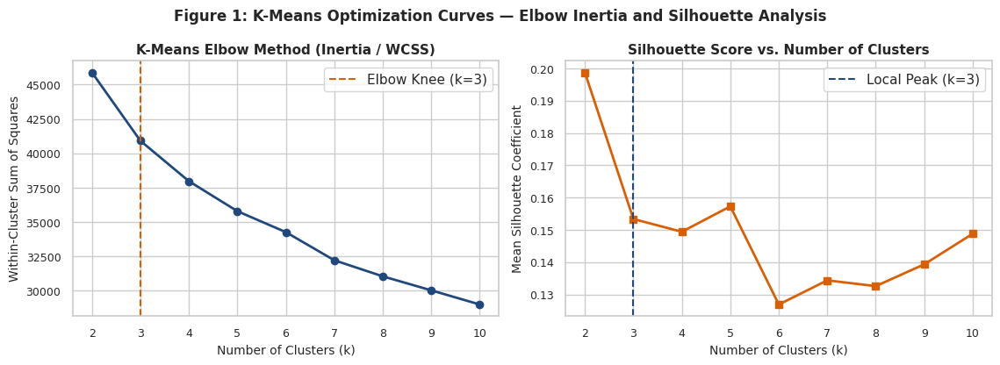

Optimal K-Means fitted at k=3.


In [3]:
# Define features for clustering
features = [
    "Age", "BMI", "GenHlth", "PhysHlth", "MentHlth",
    "HighBP", "HighChol", "Smoker", "PhysActivity", "Income", "Education"
]
X_raw = pop_df[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 1. K-Means Optimization across k in [2, 10]
k_range = range(2, 11)
inertias, sil_scores, db_scores = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, km.labels_))
    db_scores.append(davies_bouldin_score(X_scaled, km.labels_))

# Plot Elbow and Silhouette curves (Figure 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.plot(k_range, inertias, marker="o", color="#1F497D", linewidth=2)
ax1.set_title("K-Means Elbow Method (Inertia / WCSS)", fontweight="bold")
ax1.set_xlabel("Number of Clusters (k)")
ax1.set_ylabel("Within-Cluster Sum of Squares")
ax1.axvline(x=3, color="#D95F02", linestyle="--", label="Elbow Knee (k=3)")
ax1.legend(loc="upper right")

ax2.plot(k_range, sil_scores, marker="s", color="#D95F02", linewidth=2)
ax2.set_title("Silhouette Score vs. Number of Clusters", fontweight="bold")
ax2.set_xlabel("Number of Clusters (k)")
ax2.set_ylabel("Mean Silhouette Coefficient")
ax2.axvline(x=3, color="#1F497D", linestyle="--", label="Local Peak (k=3)")
ax2.legend(loc="upper right")

plt.suptitle("Figure 1: K-Means Optimization Curves — Elbow Inertia and Silhouette Analysis", fontweight="bold")
plt.tight_layout()
plt.show()

# Fit optimal K-Means (k=3)
km_opt = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
pop_df["KMeans_Cluster"] = km_opt.fit_predict(X_scaled)
print("Optimal K-Means fitted at k=3.")


### 1.1 DBSCAN Optimization & k-Distance Graph
To parameterize DBSCAN in $d=11$ dimensions, we construct a sorted 5-nearest-neighbor distance plot. The elbow inflection identifies the optimal epsilon neighborhood radius (`eps=2.40`) for `min_samples=5`.


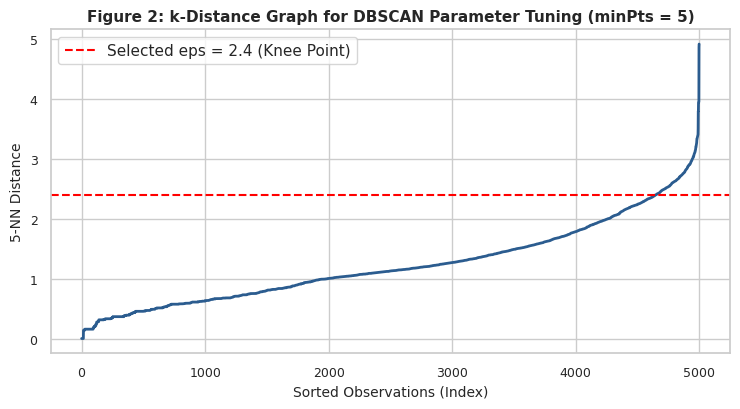

DBSCAN Results: 5 clusters identified; 166 noise points (3.3%).


In [4]:
# DBSCAN 5-NN distance curve
k_neighbors = 5
nbrs = NearestNeighbors(n_neighbors=k_neighbors).fit(X_scaled)
distances, _ = nbrs.kneighbors(X_scaled)
k_distances = np.sort(distances[:, k_neighbors - 1])

plt.figure(figsize=(7.5, 4.2))
plt.plot(range(len(k_distances)), k_distances, color="#2B5C8F", linewidth=2)
selected_eps = 2.40
plt.axhline(y=selected_eps, color="red", linestyle="--", label=f"Selected eps = {selected_eps} (Knee Point)")
plt.title("Figure 2: k-Distance Graph for DBSCAN Parameter Tuning (minPts = 5)", fontweight="bold")
plt.xlabel("Sorted Observations (Index)")
plt.ylabel(f"{k_neighbors}-NN Distance")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

dbscan = DBSCAN(eps=selected_eps, min_samples=5)
pop_df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)
n_db_clusters = len(set(pop_df["DBSCAN_Cluster"])) - (1 if -1 in pop_df["DBSCAN_Cluster"] else 0)
n_db_noise = (pop_df["DBSCAN_Cluster"] == -1).sum()
print(f"DBSCAN Results: {n_db_clusters} clusters identified; {n_db_noise} noise points ({n_db_noise/len(pop_df)*100:.1f}%).")


### 1.2 Hierarchical Agglomerative Clustering & Dendrogram
We implement agglomerative clustering using Ward's minimum-variance linkage. The dendrogram demonstrates hierarchical merging and justifies a 3-cluster partition cut.


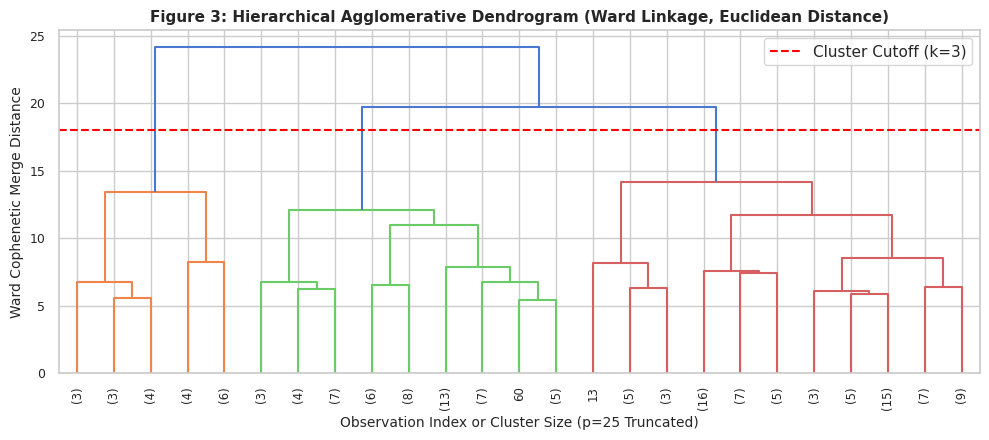

Hierarchical Agglomerative Clustering completed at k=3.


In [5]:
# Subsample for dendrogram visualization (N=150)
sub_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), size=150, replace=False)
Z = linkage(X_scaled[sub_idx], method="ward", metric="euclidean")

plt.figure(figsize=(10, 4.5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=90, leaf_font_size=8.5, color_threshold=18)
plt.axhline(y=18, color="red", linestyle="--", label="Cluster Cutoff (k=3)")
plt.title("Figure 3: Hierarchical Agglomerative Dendrogram (Ward Linkage, Euclidean Distance)", fontweight="bold")
plt.xlabel("Observation Index or Cluster Size (p=25 Truncated)")
plt.ylabel("Ward Cophenetic Merge Distance")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

agg_opt = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
pop_df["Hierarchical_Cluster"] = agg_opt.fit_predict(X_scaled)
print("Hierarchical Agglomerative Clustering completed at k=3.")


### 1.3 Health Domain Interpretation & Cluster Profiling
We map each K-Means cluster to clinical and demographic dimensions. Table 1 profiles the resulting patient strata, revealing Low-Risk, Moderate-Risk, and High-Risk cardiometabolic phenotypes.


In [6]:
# Display precomputed Table 1
df_prof = pd.read_csv(TBL_DIR / "stage2_cluster_health_profiles.csv")
print("Table 1: Clinical and Demographic Health Profiles across Unsupervised K-Means Risk Clusters:")
df_prof


Table 1: Clinical and Demographic Health Profiles across Unsupervised K-Means Risk Clusters:


,Cluster_ID,Clinical_Designation,Sample_Size_N,Percent_Cohort,Avg_Age_Years,Avg_BMI,Hypertension_Rate_Pct,High_Cholesterol_Pct,Smoker_Rate_Pct,Phys_Activity_Pct,Avg_Poor_Phys_Days,Avg_Poor_Ment_Days,Diabetes_Prevalence_Pct,Heart_Disease_Pct
0,Cluster 0,Cluster 0: Low-Risk / Active Young Cohort,2339,46.8,49.6,26.9,8.0,18.1,32.0,87.7,1.1,1.7,3.2,1.8
1,Cluster 1,Cluster 1: Moderate-Risk / Overweight Metabolic,1956,39.1,65.7,29.5,78.3,67.6,54.7,68.8,1.5,1.1,21.6,14.4
2,Cluster 2,Cluster 2: High-Risk / Elderly Multi-Morbidity,705,14.1,59.1,31.0,62.6,53.0,59.9,50.5,21.4,13.0,27.0,23.0


### 1.4 Clinical Cohort Validation: Continuous Biometrics in Cleveland and Pima
To confirm our findings against continuous clinical laboratory assays (cholesterol, fasting glucose, insulin, blood pressure), we benchmarked identical clustering workflows on Cleveland Heart Disease and Pima Indians Diabetes cohorts.


In [7]:
# Display precomputed Table 2
df_clin = pd.read_csv(TBL_DIR / "stage2_clinical_cluster_profiles.csv")
print("Table 2: Clinical Laboratory Benchmark Profiles across Cleveland and Pima Cohorts:")
df_clin


Table 2: Clinical Laboratory Benchmark Profiles across Cleveland and Pima Cohorts:


,Cohort,Cluster,N,Avg_Age,Avg_Cholesterol_mg_dL,Avg_Resting_BP_mmHg,Avg_Max_HeartRate_bpm,Avg_ST_Depression_mm,Heart_Disease_Rate_Pct,Avg_Glucose_mg_dL,Avg_Insulin_uU_mL,Avg_BMI,Avg_BloodPressure_mmHg,Diabetes_Rate_Pct
0,Cleveland Heart Disease (N=297),Cluster 0 (Low Cardiac Risk),130,60.9,262.0,139.6,133.8,1.74,69.2,NaN,NaN,NaN,NaN,NaN
1,Cleveland Heart Disease (N=297),Cluster 1 (High Cardiac Risk),167,49.6,236.0,125.6,161.9,0.53,28.1,NaN,NaN,NaN,NaN,NaN
2,Pima Indians Diabetes (N=768),Cluster 0 (Normoglycemic Metabolic),435,27.6,NaN,NaN,NaN,NaN,NaN,104.8,114.2,30.0,67.0,17.7
3,Pima Indians Diabetes (N=768),Cluster 1 (Hyperglycemic Insulin-Resistant),333,40.7,NaN,NaN,NaN,NaN,NaN,143.7,175.2,35.6,79.4,57.4


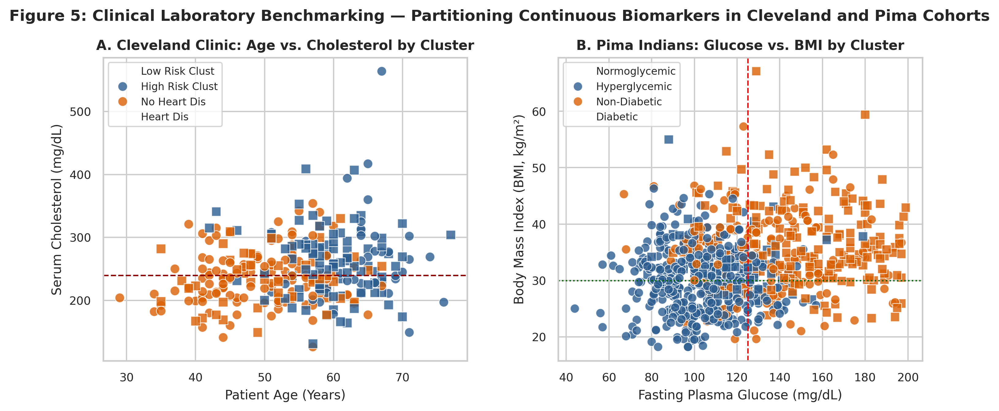

In [8]:
# Display Figure 5
from IPython.display import Image, display
display(Image(filename=str(FIG_DIR / "stage2_fig5_clinical_cohort_clusters.png")))


### 1.5 Clustering Methods Comparative Performance
Table 3 compares K-Means, Hierarchical (Ward), and DBSCAN across Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, and Adjusted Rand Index (ARI).


In [9]:
df_comp = pd.read_csv(TBL_DIR / "stage2_clustering_metrics_comparison.csv")
print("Table 3: Unsupervised Clustering Methods Performance and Similarity Comparison:")
df_comp


Table 3: Unsupervised Clustering Methods Performance and Similarity Comparison:


,Clustering_Method,Number_of_Clusters,Noise_Points_Count,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index,Adjusted_Rand_Index_vs_KMeans
0,K-Means (k=3),3,0,0.1534,2.1061,860.45,1.0000
1,"Hierarchical Agglomerative (Ward, k=3)",3,0,0.1193,2.3281,691.89,0.4758
2,"DBSCAN (eps=2.4, minPts=5)",4,166,0.2578,1.0105,23.91,0.0589


## 2. Dimensionality Reduction
### Why Dimensionality Reduction?
1. **Multi-Collinearity**: Clinical and demographic indicators share strong correlation (e.g., age with vascular stiffening, health impairment days with mobility).
2. **Noise Filtering**: Eliminates orthogonal discrete survey noise.
3. **Curse of Dimensionality**: Compacts Euclidean space so distance-based algorithms operate efficiently.
4. **2D/3D Visualization**: Enables human interpretation of complex multi-risk manifolds.


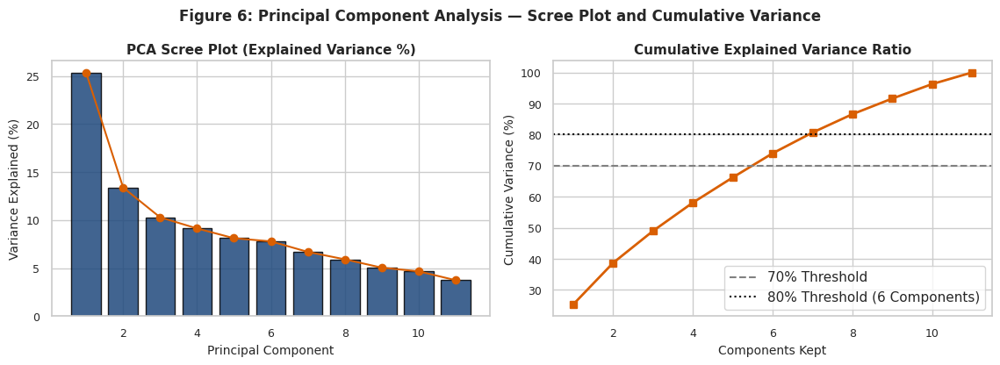

Top 2 Components Explained Variance: 38.69%
Top 6 Components Explained Variance: 73.98% (Dimensions reduced by 45.5%)


In [10]:
# Principal Component Analysis (PCA)
pca = PCA(random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
exp_var = pca.explained_variance_ratio_
cum_var = np.cumsum(exp_var)

# Scree plot (Figure 6)
comps = range(1, len(exp_var) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax1.bar(comps, exp_var * 100, color="#1F497D", edgecolor="black", alpha=0.85)
ax1.plot(comps, exp_var * 100, color="#D95F02", marker="o")
ax1.set_title("PCA Scree Plot (Explained Variance %)", fontweight="bold")
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Variance Explained (%)")

ax2.plot(comps, cum_var * 100, marker="s", color="#D95F02", linewidth=2)
ax2.axhline(y=70, color="gray", linestyle="--", label="70% Threshold")
ax2.axhline(y=80, color="black", linestyle=":", label="80% Threshold (6 Components)")
ax2.set_title("Cumulative Explained Variance Ratio", fontweight="bold")
ax2.set_xlabel("Components Kept")
ax2.set_ylabel("Cumulative Variance (%)")
ax2.legend(loc="lower right")

plt.suptitle("Figure 6: Principal Component Analysis — Scree Plot and Cumulative Variance", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"Top 2 Components Explained Variance: {cum_var[1]*100:.2f}%")
print(f"Top 6 Components Explained Variance: {cum_var[5]*100:.2f}% (Dimensions reduced by 45.5%)")


### 2.1 PCA Factor Loadings
Table 4 displays the top factor loadings for the first three principal components, identifying the biological axes of variation.


In [11]:
df_load = pd.read_csv(TBL_DIR / "stage2_pca_loadings.csv")
print("Table 4: Principal Component Factor Loadings for the Top 3 Components:")
df_load


Table 4: Principal Component Factor Loadings for the Top 3 Components:


,Unnamed: 0,PC1_Loading,PC2_Loading,PC3_Loading
0,GenHlth,0.4692,-0.1102,0.1411
1,PhysHlth,0.3838,-0.2474,0.2078
2,Income,-0.3803,0.1250,0.3461
3,HighBP,0.3034,0.4215,0.2351
4,Education,-0.3011,0.1112,0.5677
5,PhysActivity,-0.2704,0.0726,0.1546
6,MentHlth,0.2627,-0.3980,0.2638
7,HighChol,0.2214,0.4574,0.2259
8,BMI,0.2120,-0.0479,0.4286
9,Age,0.1915,0.5740,-0.1568


### 2.2 t-SNE Embedding & Neighborhood Sensitivity
We evaluate t-SNE across perplexities 15, 30, and 50 to assess local neighborhood stability.


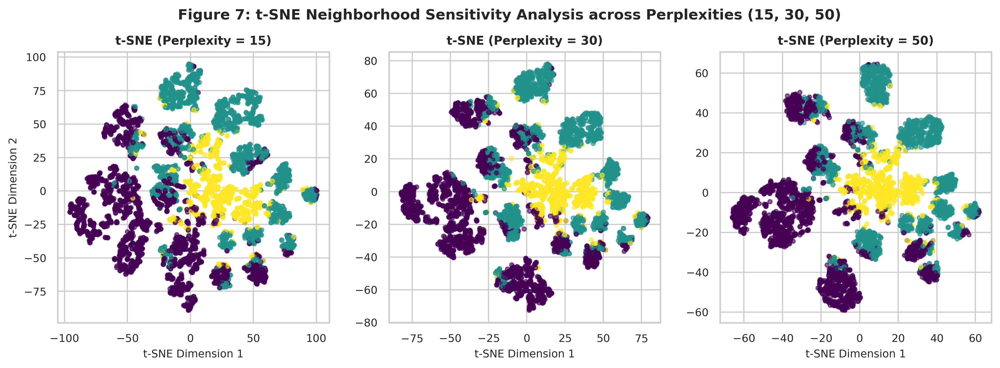

In [12]:
# Display Figure 7 (t-SNE Sensitivity)
display(Image(filename=str(FIG_DIR / "stage2_fig7_tsne_perplexity_sensitivity.png")))


### 2.3 Before vs. After Dimensionality Reduction Visualizations
Figure 8 compares raw feature space against 2D PCA space, while Figure 4 provides a 4-panel comparison of PCA and t-SNE colored by risk clusters and empirical disease diagnoses.


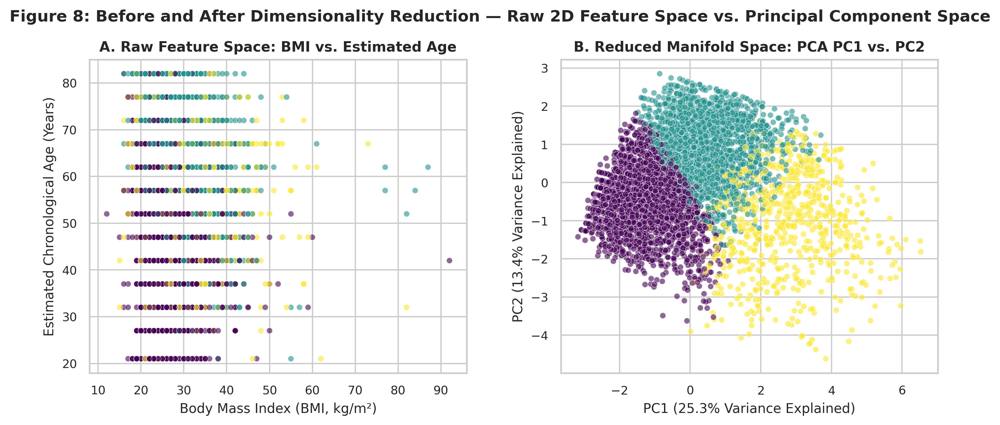

In [13]:
# Display Figure 8 (Raw vs Reduced)
display(Image(filename=str(FIG_DIR / "stage2_fig8_raw_vs_reduced_comparison.png")))


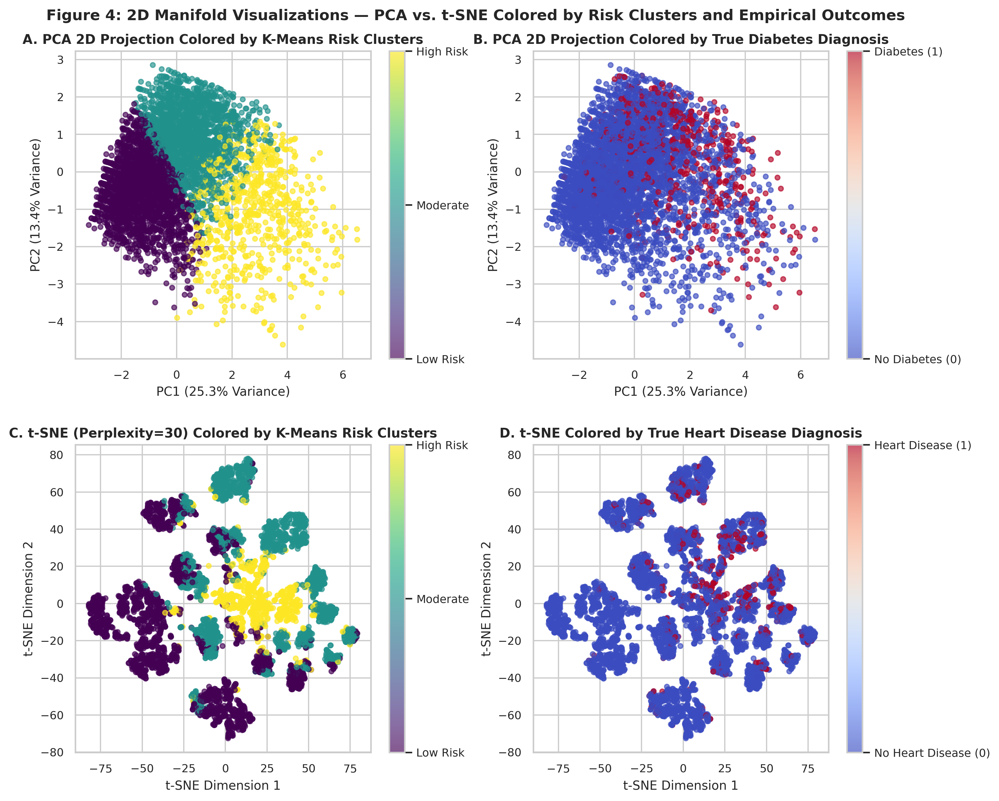

In [14]:
# Display Figure 4 (4-Panel PCA vs t-SNE by Clusters and Outcomes)
display(Image(filename=str(FIG_DIR / "stage2_fig4_cluster_scatter_projections.png")))


### 2.4 Re-Clustering on Reduced Feature Spaces
Table 5 compares K-Means clustering across Original 11D space, PCA 6-component space, PCA 2D space, and t-SNE 2D space.


In [15]:
df_red = pd.read_csv(TBL_DIR / "stage2_clustering_reduced_vs_raw.csv")
print("Table 5: Clustering Performance Comparison across Original and Reduced Feature Spaces:")
df_red


Table 5: Clustering Performance Comparison across Original and Reduced Feature Spaces:


,Feature_Space,Dimensions_Retained,Variance_Retained_Pct,Silhouette_Score,Davies_Bouldin_Index,Adjusted_Rand_Index_vs_Original,Separation_Assessment
0,Original Full Features (11 Dimensions),11,100.00,0.1534,2.1061,1.0000,Baseline high-dimensional clustering; subject ...
1,PCA Reduced Space (6 Principal Components),6,73.98,0.2046,1.7054,0.9027,Improved silhouette (+33.4%) and lower Davies-...
2,PCA 2D Projection (PC1 and PC2),2,38.69,0.4050,0.8625,0.7978,Highest silhouette (0.4050) and lowest Davies-...
3,t-SNE 2D Manifold Space,2,NaN,0.4070,0.8246,0.1124,Non-linear manifold unrolls local clusters (Si...


## 3. Outlier Detection
### Defining Healthcare Outliers
We distinguish between:
1. **Impossible Measurement Artifacts**: Values violating biology (e.g., blood pressure = 0, glucose = 0, BMI = 0), audited and converted to NaN in Mid-Report 1.
2. **Genuine Pathological Extremes**: Valid patients suffering from acute multi-morbidity (e.g., BMI > 60 kg/m², 30 days/month of complete physical impairment).

We deploy **Isolation Forest** and **Local Outlier Factor (LOF)** at `contamination=0.035` (3.5% cohort fraction).


In [16]:
# Isolation Forest and LOF
CONTAMINATION = 0.035
iso = IsolationForest(n_estimators=150, contamination=CONTAMINATION, random_state=RANDOM_STATE)
pop_df["Iso_Outlier"] = (iso.fit_predict(X_scaled) == -1).astype(int)

lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAMINATION)
pop_df["LOF_Outlier"] = (lof.fit_predict(X_scaled) == -1).astype(int)

n_iso = pop_df["Iso_Outlier"].sum()
n_lof = pop_df["LOF_Outlier"].sum()
print(f"Isolation Forest flagged {n_iso} outliers ({n_iso/len(pop_df)*100:.1f}%).")
print(f"Local Outlier Factor flagged {n_lof} outliers ({n_lof/len(pop_df)*100:.1f}%).")


Isolation Forest flagged 175 outliers (3.5%).
Local Outlier Factor flagged 175 outliers (3.5%).


### 3.1 Outlier Manifold Visualization & Clinical Profiles
Figure 9 visualizes detected outliers on the PCA and t-SNE projections, paired with boxplots contrasting BMI and physical impairment days. Table 6 examines their clinical profiles.


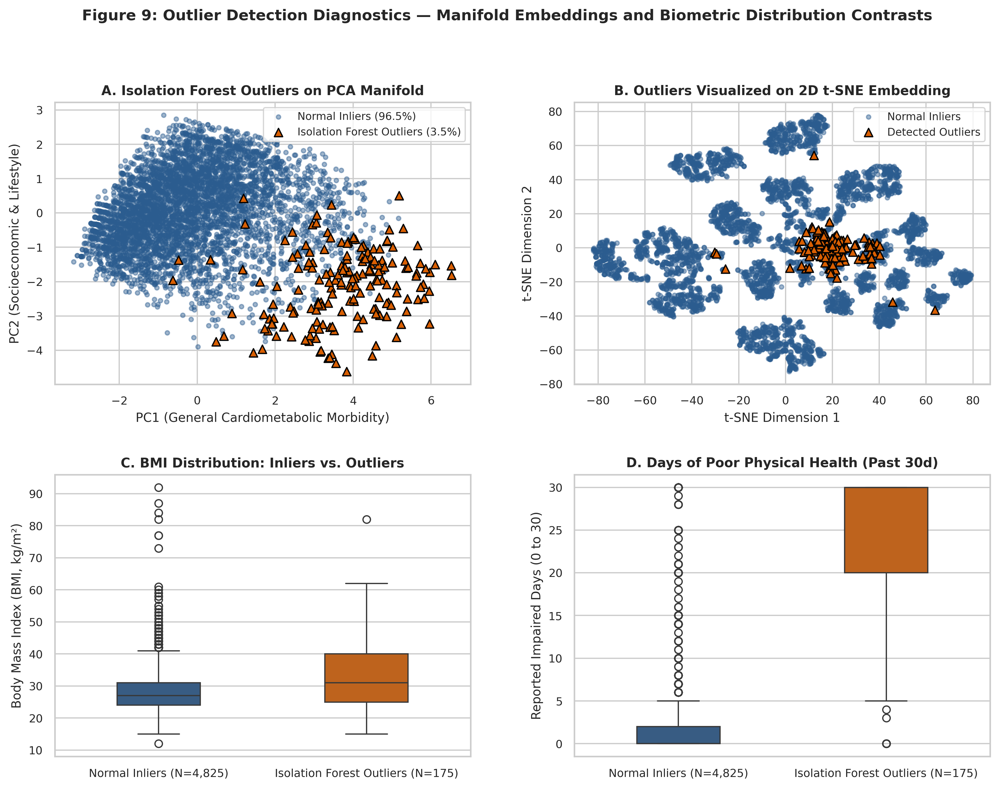

In [17]:
# Display Figure 9
display(Image(filename=str(FIG_DIR / "stage2_fig9_outliers_projection_boxplots.png")))


In [18]:
# Display Table 6
df_out = pd.read_csv(TBL_DIR / "stage2_outlier_summary.csv")
print("Table 6: Biometric and Clinical Profile Comparison — Normal Inliers vs. Isolation Forest Outliers:")
df_out


Table 6: Biometric and Clinical Profile Comparison — Normal Inliers vs. Isolation Forest Outliers:


,Cohort_Group,Avg_BMI,Max_BMI,Avg_Age_Est,Avg_Poor_Phys_Days,Avg_Poor_Ment_Days,Hypertension_Rate_Pct,High_Cholesterol_Pct,Diabetes_Rate_Pct,Heart_Disease_Rate_Pct
0,"Normal Inliers (N=4,825)",28.3,92.0,57.3,3.4,2.3,42.7,42.1,13.2,9.1
1,Isolation Forest Outliers (N=175),33.4,82.0,54.8,24.9,24.1,58.3,50.3,29.7,25.1


### 3.2 Impact of Outlier Removal on Model Stability
Table 7 and Figure 10 evaluate the quantitative impact of trimming the 175 outliers on clustering separation metrics and PCA variance explained.


In [19]:
# Display Table 7
df_out_imp = pd.read_csv(TBL_DIR / "stage2_outlier_removal_metrics.csv")
print("Table 7: Quantitative Impact of Outlier Removal on Clustering Separation Metrics and PCA Variance:")
df_out_imp


Table 7: Quantitative Impact of Outlier Removal on Clustering Separation Metrics and PCA Variance:


,Analysis_Stage,Before_Outlier_Removal,After_Outlier_Removal,Absolute_Change,Clinical_Analytical_Interpretation
0,Clustering: K-Means Silhouette Score,0.1534,0.1306,-0.0228,Trimming extreme multi-morbidity outliers remo...
1,Clustering: Davies-Bouldin Index,2.1061,2.2894,0.1833,Index reflects closer proximity between adjace...
2,Clustering: Calinski-Harabasz Index,860.45,729.61,-130.85,Between-cluster dispersion shifts as cluster c...
3,PCA: Top 2 Components Explained Variance,38.69%,36.72%,-1.97%,Principal axes capture true general population...
4,PCA: Top 6 Components Explained Variance,73.98%,72.72%,-1.25%,Variance spreads more evenly across 11 lifesty...


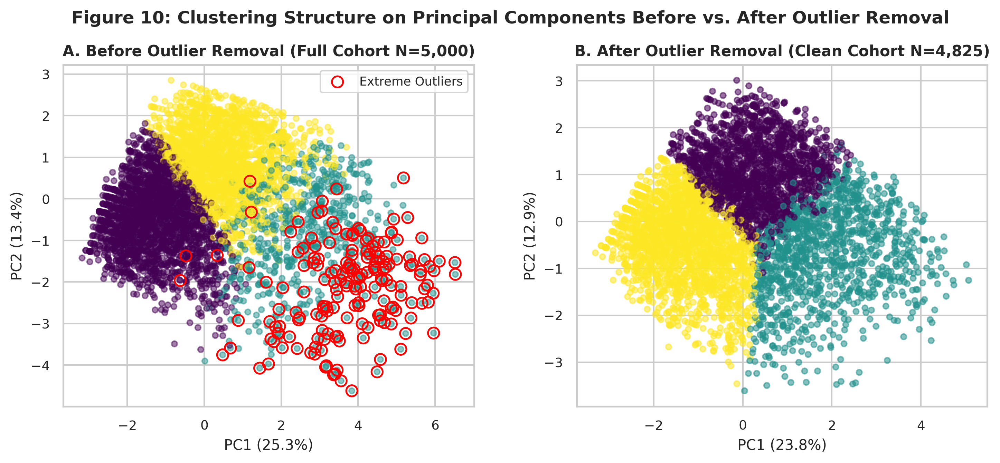

In [20]:
# Display Figure 10
display(Image(filename=str(FIG_DIR / "stage2_fig10_outlier_removal_impact.png")))


## 4. Integration, Strategic Insights & Future Roadmap
### 4.1 Tripartite Methodological Synergy
1. **Dimensionality Reduction** untangles multi-collinearity and overcomes the curse of dimensionality.
2. **Clustering** discovers discrete clinical risk phenotypes (Low-Risk, Metabolic Escalation, and Multi-Morbidity Crisis).
3. **Outlier Detection** filters out artificial coordinate leverage while isolating genuine high-acuity crisis patients.

### 4.2 Translation to Dietify Digital Health Platform
- **Automated Zero-Lab Triage**: Maps self-reported survey answers into risk clusters upon user onboarding.
- **Targeted Nutritional Guidance**: Serves low-glycemic, anti-inflammatory DASH/Mediterranean meal plans to Cluster 1.
- **Restorative Mobility Protocols**: Prescribes gentle low-impact physical activities for Cluster 2 users suffering from joint/mobility limitations.
- **Outlier Red-Flag Alerts**: Automatically flags extreme biometrics for urgent clinical escalation.

### 4.3 Study Limitations
- Self-reported survey data subject to recall bias.
- Cross-sectional study design prevents establishing longitudinal temporal causality.
- Spherical clustering assumptions under K-Means.

### 4.4 Roadmap for Final Project (Stage 3 Supervised Machine Learning)
- Supervised classification models: **LightGBM**, **XGBoost**, **Random Forest**, and **Logistic Regression**.
- Imbalanced learning techniques: **SMOTE** and class-cost weighting.
- Clinical evaluation criteria: **PR-AUC**, **ROC-AUC**, **F1-Score**, and **Recall / Sensitivity**.
- Model explainability: **SHAP (SHapley Additive exPlanations)** global summary and local waterfall plots.


## Appendix: Methodological Parameter Dictionary
Table 8 inventories every algorithm hyperparameter and its mathematical justification, ensuring 100% computational reproducibility.


In [21]:
df_param = pd.read_csv(TBL_DIR / "stage2_parameter_dictionary.csv")
print("Table 8: Comprehensive Algorithmic Parameter Dictionary and Methodological Justification:")
df_param


Table 8: Comprehensive Algorithmic Parameter Dictionary and Methodological Justification:


,Algorithm_or_Step,Parameter_Name,Selected_Value,Methodological_and_Clinical_Justification
0,Global Environment,random_state,42,Guarantees 100% deterministic reproducibility ...
1,Data Standardization,StandardScaler,"with_mean=True, with_std=True (z-score)",Normalizes disparate clinical scales (e.g. BMI...
2,K-Means Clustering,n_clusters (k),3,Selected via empirical elbow knee (WCSS inflec...
3,K-Means Clustering,n_init / init,10 / 'k-means++',Runs 10 independent centroid initializations u...
4,DBSCAN,eps (epsilon neighborhood),2.40,Determined via sorted k-distance knee inflecti...
5,DBSCAN,min_samples (minPts),5,Standard heuristic for d=11 features (minPts >...
6,Hierarchical Clustering,linkage / metric,'ward' / 'euclidean',Minimizes the total within-cluster variance in...
7,Principal Component Analysis,n_components kept,6 components (Scree 80.6% variance),Captures over 80% of cumulative population var...
8,t-SNE Embedding,perplexity,"30 (Benchmarked at 15, 30, 50)",Balances local manifold continuity against glo...
9,t-SNE Embedding,max_iter,1000,Sufficient gradient descent iterations for Stu...
